In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.linear_model import LinearRegression

In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet'

# old file file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/final_paper_files/filtered_merged_26cols_pps_smap_no2_soil_state_localtime.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df.head(7)

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas
1,36.05,-91.05,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,47.916667,0.0,33.333333,0.000000,2.083333,Arkansas
2,36.05,-90.95,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,1.515152,0.0,46.212121,22.727273,26.515152,Arkansas
3,36.05,-90.85,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,8.333333,0.0,65.972222,2.777778,11.805556,Arkansas
4,36.05,-90.75,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,1.515152,0.0,76.515152,0.000000,4.545455,Arkansas
5,36.05,-90.45,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.0,0.0,0.0,0.000000,0.0,83.333333,0.000000,15.277778,Arkansas
6,36.05,-90.35,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,1.515152,0.0,0.0,0.0,6.818182,0.0,15.151515,5.303030,25.757576,Arkansas


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name'],
      dtype='object')

In [5]:
df =df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])
df =df.sort_values(["grid_lat", "grid_lon", "datetime"]).reset_index(drop=True)
df["pulse_start"] = df["pulse_start"].fillna(False)

pulse_df = df[df["pulse_start"] == True].copy()

In [6]:
from tqdm import tqdm 
from sklearn.linear_model import LinearRegression

In [7]:
records =[]
window_hours = 24 * 5  #5 days

for _, row in tqdm(pulse_df.iterrows(), total=len(pulse_df), desc="computing pre-pulse slopes"):
    lat = row["grid_lat"]
    lon= row["grid_lon"]
    t0 = row["datetime"]
    
    sub =df[(df["grid_lat"] ==lat) & (df["grid_lon"] ==lon)]
    
    # get 5 days before pulse
    window = sub[
        (sub["datetime"] < t0) &
        (sub["datetime"] >= t0 - pd.Timedelta(hours=window_hours))
    ].copy()
    
    # drop missing SM
    window = window.dropna(subset=["sm_surface"])
    
    if len(window) < 20:
        slope = np.nan
    else:
        t =(window["datetime"] - window["datetime"].min()).dt.total_seconds()/3600
        y =window["sm_surface"].values
        
        model=LinearRegression().fit(t.values.reshape(-1, 1), y)
        slope=model.coef_[0]
    
    records.append({
        "grid_lat": lat,
        "grid_lon": lon,
        "datetime": t0,
        "pre_slope": slope})

slope_df = pd.DataFrame(records)

computing pre-pulse slopes: 100%|██████████| 2009/2009 [02:21<00:00, 14.16it/s]


In [8]:
threshold =0

def classify(s):
    if pd.isna(s):
        return "no data"
    elif s > threshold:
        return "increasing"
    elif s < -threshold:
        return "decreasing"
    else:
        return "flat"

slope_df["sm_class"] = slope_df["pre_slope"].apply(classify)

In [9]:
df = df.merge(slope_df, on=["grid_lat", "grid_lon", "datetime"], how="left")

In [10]:
print(slope_df["sm_class"].value_counts())

sm_class
decreasing    1245
increasing     764
Name: count, dtype: int64


In [11]:
df.head(7)

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
1,36.05,-91.15,NaN,2024-02-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
2,36.05,-91.15,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
3,36.05,-91.15,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
4,36.05,-91.15,NaN,2024-03-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
5,36.05,-91.15,NaN,2024-03-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
6,36.05,-91.15,NaN,2024-03-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN


In [12]:
output_file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_with_incdec.parquet'
df.to_parquet(output_file, engine='pyarrow')

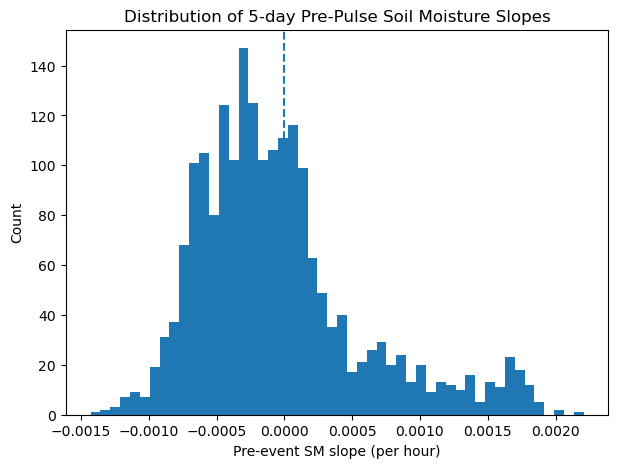

In [13]:
valid_slopes = slope_df["pre_slope"].dropna()

plt.figure(figsize=(7,5))
plt.hist(valid_slopes, bins=50)
plt.axvline(0, linestyle="--")

plt.xlabel("Pre-event SM slope (per hour)")
plt.ylabel("Count")
plt.title("Distribution of 5-day Pre-Pulse Soil Moisture Slopes")

plt.show()

In [14]:
df.head()

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
1,36.05,-91.15,NaN,2024-02-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
2,36.05,-91.15,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
3,36.05,-91.15,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN
4,36.05,-91.15,NaN,2024-03-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,NaN


In [15]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class'],
      dtype='object')

In [16]:
slope_df

,grid_lat,grid_lon,datetime,pre_slope,sm_class
0,36.05,-91.15,2024-04-13 15:00:00,0.000848,increasing
1,36.05,-91.05,2024-06-13 23:00:00,-0.000743,decreasing
2,36.05,-90.85,2024-06-13 23:00:00,-0.000802,decreasing
3,36.05,-89.75,2024-06-13 21:00:00,-0.000624,decreasing
4,36.05,-89.65,2024-06-13 21:00:00,-0.000543,decreasing
...,...,...,...,...,...
2004,48.45,-101.05,2024-06-28 17:00:00,0.000190,increasing
2005,48.45,-100.25,2024-07-06 15:00:00,-0.000356,decreasing
2006,48.45,-100.15,2024-07-06 15:00:00,-0.000426,decreasing
2007,48.55,-100.55,2024-07-06 15:00:00,-0.000302,decreasing


# hour of day and increasing/decreasing cases

In [17]:
plot_df = slope_df.merge(
    df[["grid_lat", "grid_lon", "datetime", "datetime_local"]],
    on=["grid_lat", "grid_lon", "datetime"],
    how="left"
)

plot_df["hour"] = pd.to_datetime(plot_df["datetime_local"]).dt.hour
plot_df = plot_df[plot_df["sm_class"].isin(["increasing", "decreasing"])]



In [18]:
import seaborn as sns

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


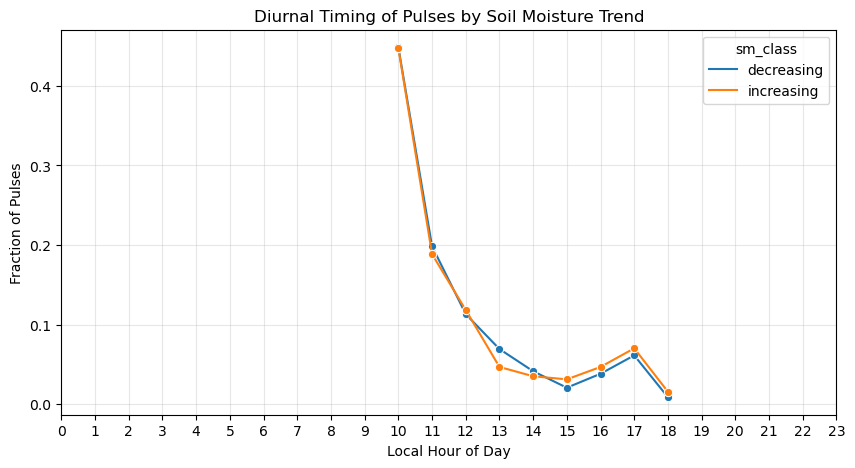

In [19]:
# count pulses per hour per class
counts = (plot_df.groupby(["sm_class", "hour"]).size().reset_index(name="count"))

# normalize within each class
counts["fraction"] = counts.groupby("sm_class")["count"].transform(lambda x: x / x.sum())

plt.figure(figsize=(10,5))
sns.lineplot(data=counts,x="hour",y="fraction",hue="sm_class",marker="o")
plt.xlabel("Local Hour of Day")
plt.ylabel("Fraction of Pulses")
plt.title("Diurnal Timing of Pulses by Soil Moisture Trend")

plt.xticks(range(0,24))
plt.grid(alpha=0.3)
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


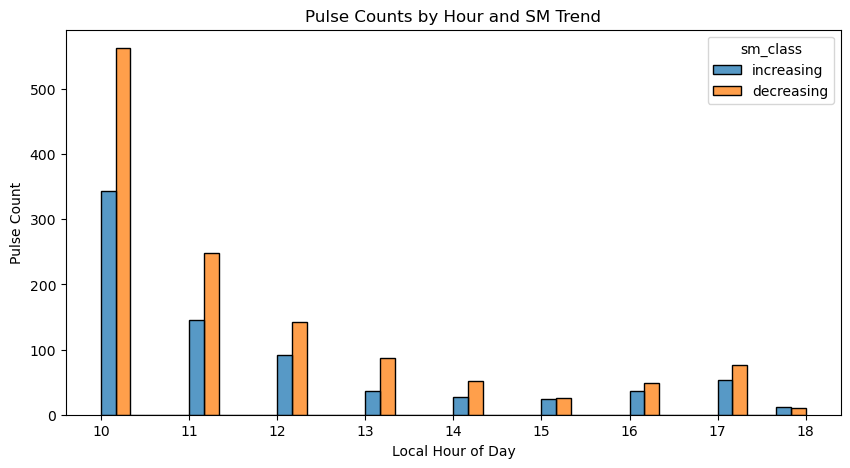

In [20]:
plt.figure(figsize=(10,5))

sns.histplot(data=plot_df,x="hour",hue="sm_class",bins=24,multiple="dodge")
plt.xlabel("Local Hour of Day")
plt.ylabel("Pulse Count")
plt.title("Pulse Counts by Hour and SM Trend")
plt.show()

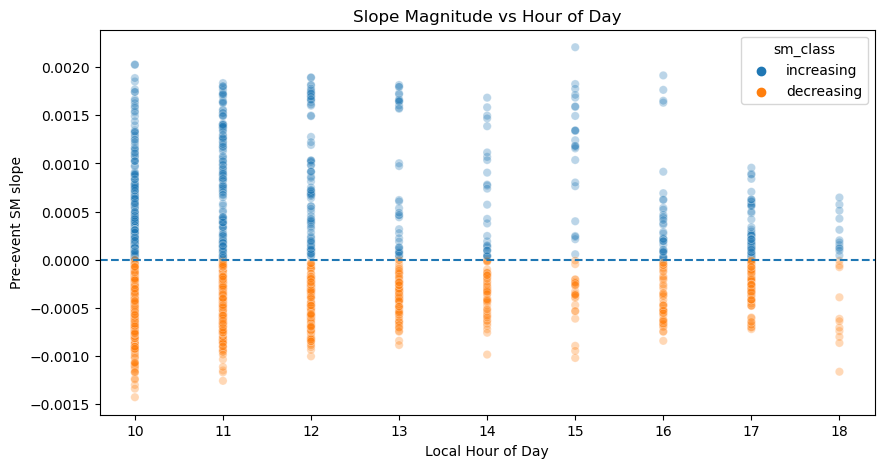

In [21]:
plt.figure(figsize=(10,5))

sns.scatterplot(data=plot_df,x="hour",y="pre_slope",hue="sm_class",alpha=0.3)
plt.axhline(0, linestyle="--")
plt.xlabel("Local Hour of Day")
plt.ylabel("Pre-event SM slope")
plt.title("Slope Magnitude vs Hour of Day")
plt.show()

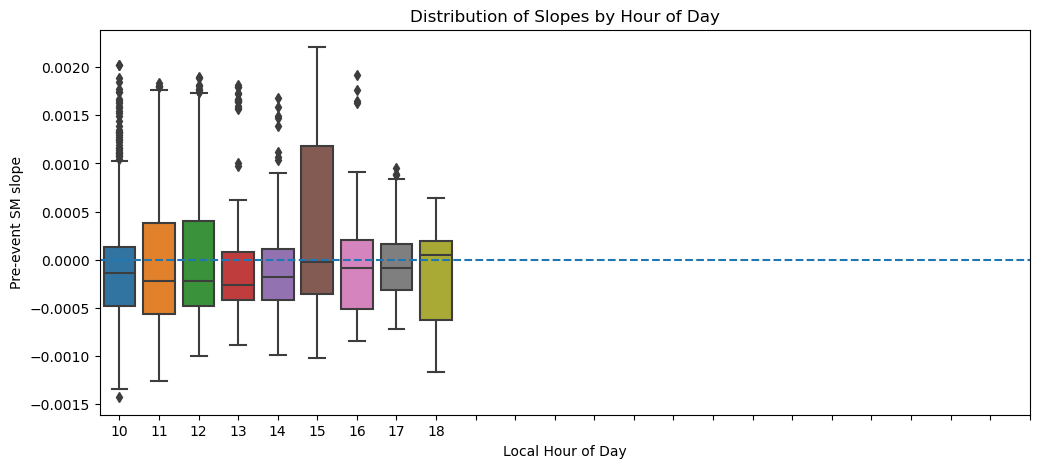

In [22]:
plt.figure(figsize=(12,5))

sns.boxplot(data=plot_df,x="hour",y="pre_slope")
plt.axhline(0, linestyle="--")
plt.xlabel("Local Hour of Day")
plt.ylabel("Pre-event SM slope")
plt.title("Distribution of Slopes by Hour of Day")
plt.xticks(range(0,24))
plt.show()

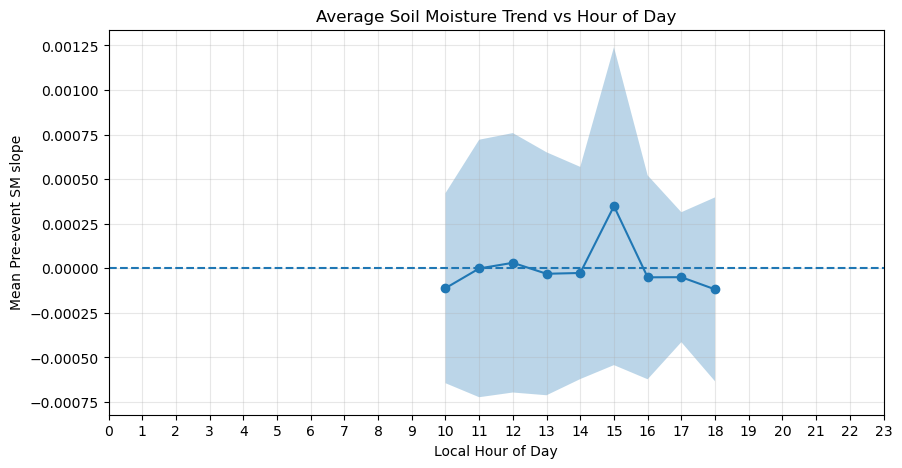

In [23]:
hourly_stats = (plot_df.groupby("hour")["pre_slope"].agg(["mean", "std", "count"])
                .reset_index())

plt.figure(figsize=(10,5))
plt.plot(hourly_stats["hour"], hourly_stats["mean"], marker="o")
plt.fill_between(hourly_stats["hour"],
                 hourly_stats["mean"] - hourly_stats["std"],
                 hourly_stats["mean"] + hourly_stats["std"],
                 alpha=0.3)

plt.axhline(0, linestyle="--")
plt.xlabel("Local Hour of Day")
plt.ylabel("Mean Pre-event SM slope")
plt.title("Average Soil Moisture Trend vs Hour of Day")
plt.xticks(range(0,24))
plt.grid(alpha=0.3)
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


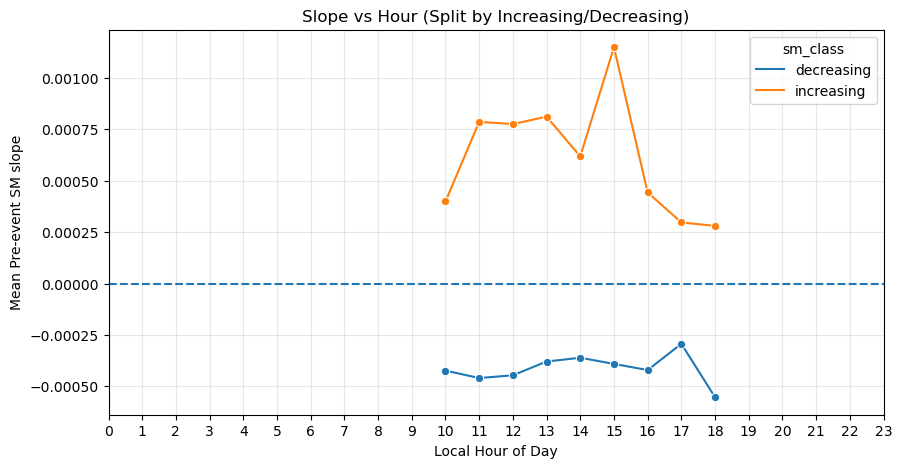

In [24]:
hourly_stats = (plot_df.groupby(["sm_class", "hour"])["pre_slope"].mean().reset_index())
plt.figure(figsize=(10,5))
sns.lineplot(data=hourly_stats, x="hour",y="pre_slope",hue="sm_class",marker="o")
plt.axhline(0, linestyle="--")
plt.xlabel("Local Hour of Day")
plt.ylabel("Mean Pre-event SM slope")
plt.title("Slope vs Hour (Split by Increasing/Decreasing)")
plt.xticks(range(0,24))
plt.grid(alpha=0.3)
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


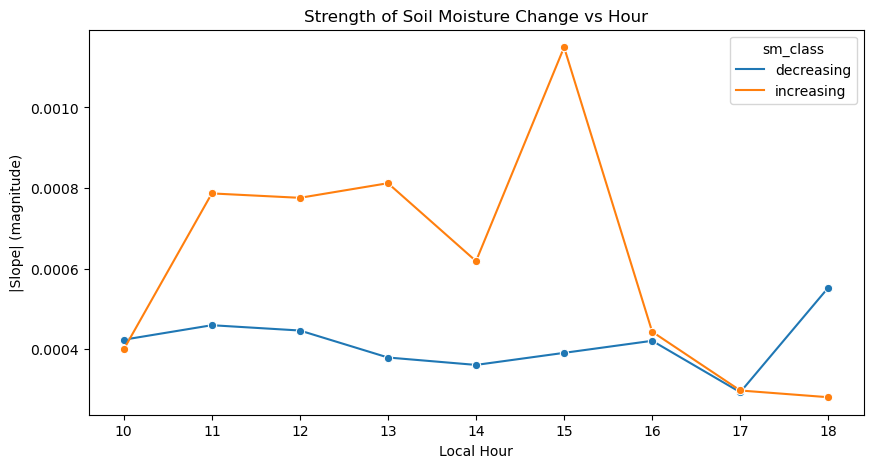

In [25]:
plot_df["slope_mag"] = plot_df["pre_slope"].abs()
hourly_mag = (plot_df.groupby(["sm_class", "hour"])["slope_mag"].mean().reset_index())
plt.figure(figsize=(10,5))
sns.lineplot(data=hourly_mag, x="hour", y="slope_mag",hue="sm_class",marker="o")

plt.xlabel("Local Hour")
plt.ylabel("|Slope| (magnitude)")
plt.title("Strength of Soil Moisture Change vs Hour")
plt.show()

# temperature effect?

In [26]:
df_with_class = df.merge(
    slope_df[["grid_lat", "grid_lon", "datetime", "sm_class"]],
    on=["grid_lat", "grid_lon", "datetime"],
    how="left"
)

In [27]:
records = []

WINDOW_HOURS = 24 * 5  # 5 days before

for _, row in slope_df.iterrows():
    lat, lon, t0, sm_class = row["grid_lat"], row["grid_lon"], row["datetime"], row["sm_class"]
    
    sub = df[
        (df["grid_lat"] == lat) &
        (df["grid_lon"] == lon)
    ]
    
    window = sub[
        (sub["datetime"] <= t0) &
        (sub["datetime"] >= t0 - pd.Timedelta(hours=WINDOW_HOURS))
    ].copy()
    
    if window.empty:
        continue
    
    # create lag (in hours relative to pulse)
    window["lag_hours"] = (
        (window["datetime"] - t0).dt.total_seconds() / 3600
    ).astype(int)
    
    window["sm_class"] = sm_class
    
    records.append(window)

events_df = pd.concat(records, ignore_index=True)

In [28]:
precip_comp = (
    events_df.groupby(["sm_class", "lag_hours"])["h_precip_mm"]
    .mean()
    .reset_index()
)

In [29]:
temp_comp = (
    events_df.groupby(["sm_class", "lag_hours"])["surface_temp"]
    .mean()
    .reset_index()
)

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


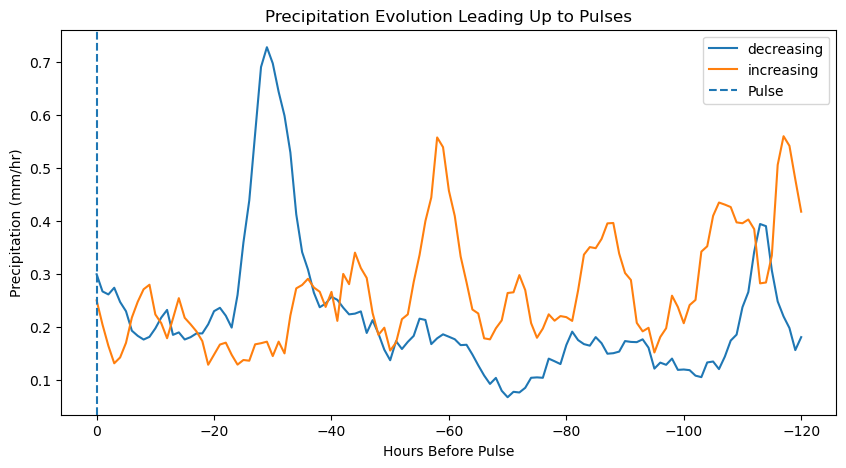

In [30]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=precip_comp,
    x="lag_hours",
    y="h_precip_mm",
    hue="sm_class"
)

plt.axvline(0, linestyle="--", label="Pulse")
plt.xlabel("Hours Before Pulse")
plt.ylabel("Precipitation (mm/hr)")
plt.title("Precipitation Evolution Leading Up to Pulses")

plt.legend()
plt.gca().invert_xaxis()  # so time flows → toward pulse

plt.show()